In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [3]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
])

In [5]:
train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

100%|██████████| 170M/170M [00:24<00:00, 6.90MB/s]


In [6]:
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Training images: 50000
Testing images: 10000


In [7]:
classes = train_dataset.classes

print(classes)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [8]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Class:", classes[label])

Image shape: torch.Size([3, 32, 32])
Label: 6
Class: frog


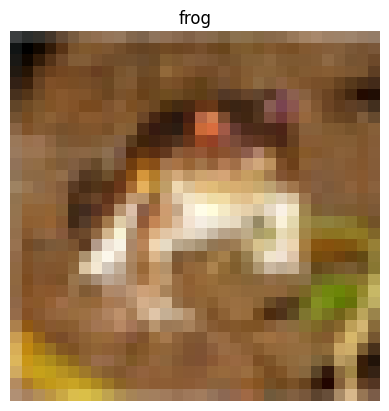

In [9]:
import matplotlib.pyplot as plt

image, label = train_dataset[0]

plt.imshow(image.permute(1, 2, 0))
plt.title(classes[label])
plt.axis("off")
plt.show()

In [10]:
image.permute(1, 2, 0)

tensor([[[0.2314, 0.2431, 0.2471],
         [0.1686, 0.1804, 0.1765],
         [0.1961, 0.1882, 0.1686],
         ...,
         [0.6196, 0.5176, 0.4235],
         [0.5961, 0.4902, 0.4000],
         [0.5804, 0.4863, 0.4039]],

        [[0.0627, 0.0784, 0.0784],
         [0.0000, 0.0000, 0.0000],
         [0.0706, 0.0314, 0.0000],
         ...,
         [0.4824, 0.3451, 0.2157],
         [0.4667, 0.3255, 0.1961],
         [0.4784, 0.3412, 0.2235]],

        [[0.0980, 0.0941, 0.0824],
         [0.0627, 0.0275, 0.0000],
         [0.1922, 0.1059, 0.0314],
         ...,
         [0.4627, 0.3294, 0.1961],
         [0.4706, 0.3294, 0.1961],
         [0.4275, 0.2863, 0.1647]],

        ...,

        [[0.8157, 0.6667, 0.3765],
         [0.7882, 0.6000, 0.1333],
         [0.7765, 0.6314, 0.1020],
         ...,
         [0.6275, 0.5216, 0.2745],
         [0.2196, 0.1216, 0.0275],
         [0.2078, 0.1333, 0.0784]],

        [[0.7059, 0.5451, 0.3765],
         [0.6784, 0.4824, 0.1647],
         [0.

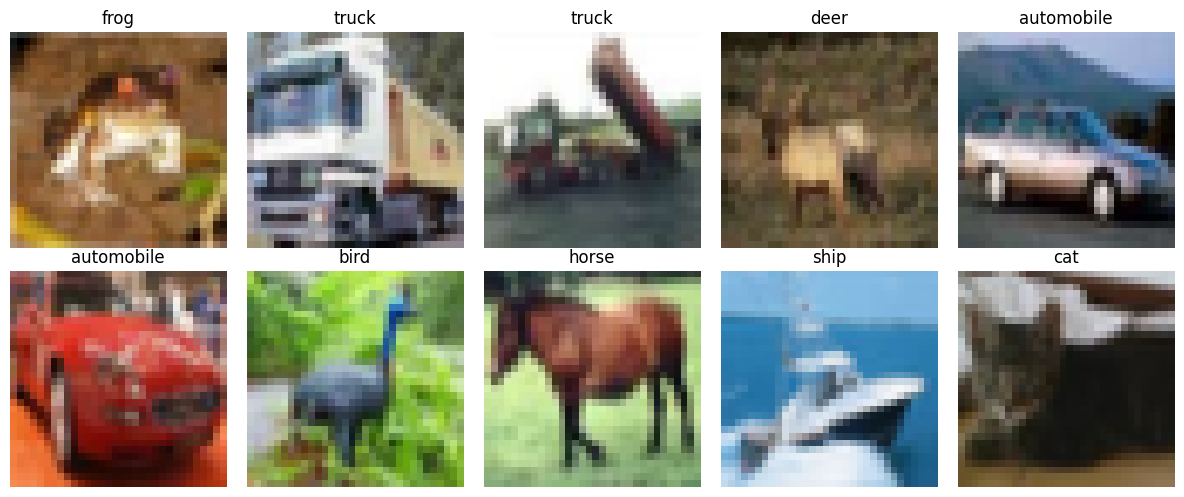

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Number of training batches:", len(train_loader))
print("Number of testing batches:", len(test_loader))

Number of training batches: 782
Number of testing batches: 157


In [13]:
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Batch image shape: torch.Size([64, 3, 32, 32])
Batch label shape: torch.Size([64])


In [14]:
import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        self.fc1 = nn.Linear(
            64 * 8 * 8,
            128
        )

        self.fc2 = nn.Linear(
            128,
            10
        )

    def forward(self, x):

        x = F.relu(self.conv1(x))
        x = self.pool(x)

        x = F.relu(self.conv2(x))
        x = self.pool(x)

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x

In [15]:
model = CNN()

print(model)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [16]:
model = model.to(device)

print("Model is using:", device)

Model is using: cuda


In [17]:
criterion = nn.CrossEntropyLoss()

In [18]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [19]:
num_epochs = 10

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # 1. Forward pass
        outputs = model(images)

        # 2. Calculate loss
        loss = criterion(outputs, labels)

        # 3. Clear old gradients
        optimizer.zero_grad()

        # 4. Backpropagation
        loss.backward()

        # 5. Update weights
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch+1}/{num_epochs}], "
        f"Loss: {average_loss:.4f}"
    )

Epoch [1/10], Loss: 1.4751
Epoch [2/10], Loss: 1.1070
Epoch [3/10], Loss: 0.9593
Epoch [4/10], Loss: 0.8703
Epoch [5/10], Loss: 0.7898
Epoch [6/10], Loss: 0.7166
Epoch [7/10], Loss: 0.6579
Epoch [8/10], Loss: 0.5972
Epoch [9/10], Loss: 0.5398
Epoch [10/10], Loss: 0.4815


In [20]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 71.41%


In [21]:
from sklearn.metrics import classification_report

all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.cpu().numpy())

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=classes
    )
)

              precision    recall  f1-score   support

    airplane       0.76      0.72      0.74      1000
  automobile       0.84      0.80      0.81      1000
        bird       0.68      0.54      0.60      1000
         cat       0.58      0.46      0.51      1000
        deer       0.67      0.67      0.67      1000
         dog       0.55      0.74      0.63      1000
        frog       0.73      0.82      0.78      1000
       horse       0.81      0.74      0.78      1000
        ship       0.75      0.87      0.80      1000
       truck       0.80      0.78      0.79      1000

    accuracy                           0.71     10000
   macro avg       0.72      0.71      0.71     10000
weighted avg       0.72      0.71      0.71     10000



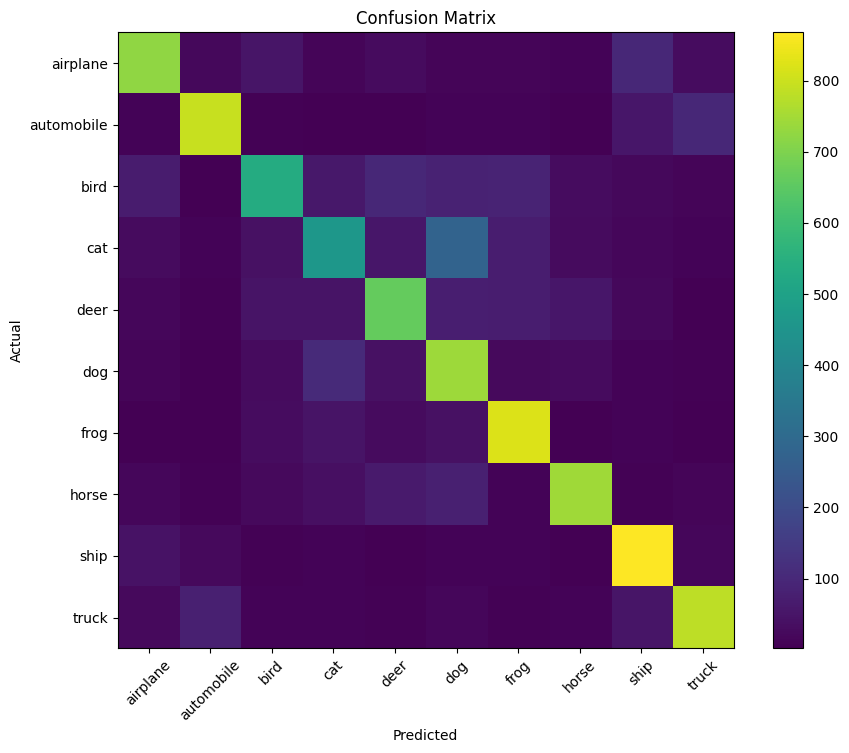

In [22]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(10, 8))

plt.imshow(cm)

plt.xticks(range(10), classes, rotation=45)
plt.yticks(range(10), classes)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.colorbar()

plt.show()

In [23]:
mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)

In [24]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

In [25]:
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

In [26]:
train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transform
)

In [27]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [28]:
class ImprovedCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.dropout = nn.Dropout(0.5)

        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = F.relu(self.conv1(x))
        x = self.pool(x)

        x = F.relu(self.conv2(x))
        x = self.pool(x)

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))

        x = self.dropout(x)

        x = self.fc2(x)

        return x

In [29]:
model = ImprovedCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [30]:
num_epochs = 15

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch+1}/{num_epochs}], "
        f"Loss: {average_loss:.4f}"
    )

Epoch [1/15], Loss: 1.7055
Epoch [2/15], Loss: 1.4611
Epoch [3/15], Loss: 1.3438
Epoch [4/15], Loss: 1.2720
Epoch [5/15], Loss: 1.2242
Epoch [6/15], Loss: 1.1859
Epoch [7/15], Loss: 1.1454
Epoch [8/15], Loss: 1.1308
Epoch [9/15], Loss: 1.1023
Epoch [10/15], Loss: 1.0827
Epoch [11/15], Loss: 1.0724
Epoch [12/15], Loss: 1.0583
Epoch [13/15], Loss: 1.0453
Epoch [14/15], Loss: 1.0307
Epoch [15/15], Loss: 1.0206


In [31]:
import torchvision.models as models

resnet = models.resnet18(weights="DEFAULT")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 185MB/s]


In [32]:
print(resnet)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [33]:
train_transform_resnet = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

test_transform_resnet = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

In [34]:
train_dataset_resnet = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform_resnet
)

test_dataset_resnet = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transform_resnet
)

In [35]:
train_loader_resnet = DataLoader(
    train_dataset_resnet,
    batch_size=64,
    shuffle=True
)

test_loader_resnet = DataLoader(
    test_dataset_resnet,
    batch_size=64,
    shuffle=False
)

In [36]:
import torch.nn as nn

resnet.fc = nn.Linear(
    resnet.fc.in_features,
    10
)

In [37]:
resnet = resnet.to(device)

In [38]:
for param in resnet.parameters():
    param.requires_grad = False

In [39]:
for param in resnet.fc.parameters():
    param.requires_grad = True

In [40]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    resnet.fc.parameters(),
    lr=0.001
)

In [41]:
num_epochs = 5

for epoch in range(num_epochs):

    resnet.train()

    running_loss = 0.0

    for images, labels in train_loader_resnet:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader_resnet)

    print(
        f"Epoch [{epoch+1}/{num_epochs}], "
        f"Loss: {average_loss:.4f}"
    )

Epoch [1/5], Loss: 0.8209
Epoch [2/5], Loss: 0.6170
Epoch [3/5], Loss: 0.5931
Epoch [4/5], Loss: 0.5805
Epoch [5/5], Loss: 0.5728


In [42]:
from sklearn.metrics import accuracy_score, classification_report

resnet.eval()

all_labels_resnet = []
all_predictions_resnet = []

with torch.no_grad():

    for images, labels in test_loader_resnet:

        images = images.to(device)

        outputs = resnet(images)

        _, predicted = torch.max(outputs, 1)

        all_labels_resnet.extend(labels.numpy())
        all_predictions_resnet.extend(predicted.cpu().numpy())

resnet_accuracy = accuracy_score(
    all_labels_resnet,
    all_predictions_resnet
)

print(f"ResNet Test Accuracy: {resnet_accuracy * 100:.2f}%")

ResNet Test Accuracy: 80.78%


In [43]:
print(
    classification_report(
        all_labels_resnet,
        all_predictions_resnet,
        target_names=classes
    )
)

              precision    recall  f1-score   support

    airplane       0.80      0.85      0.82      1000
  automobile       0.90      0.89      0.89      1000
        bird       0.74      0.76      0.75      1000
         cat       0.73      0.65      0.69      1000
        deer       0.83      0.71      0.76      1000
         dog       0.76      0.76      0.76      1000
        frog       0.81      0.88      0.84      1000
       horse       0.79      0.85      0.82      1000
        ship       0.84      0.88      0.86      1000
       truck       0.88      0.86      0.87      1000

    accuracy                           0.81     10000
   macro avg       0.81      0.81      0.81     10000
weighted avg       0.81      0.81      0.81     10000



In [44]:
print("Model Comparison")
print("-----------------------------")
print(f"Basic CNN:      {accuracy:.2f}%")
print(f"ResNet-18:      {resnet_accuracy * 100:.2f}%")

Model Comparison
-----------------------------
Basic CNN:      71.41%
ResNet-18:      80.78%


In [45]:
for param in resnet.parameters():
    param.requires_grad = False

for param in resnet.layer4.parameters():
    param.requires_grad = True

for param in resnet.fc.parameters():
    param.requires_grad = True

In [46]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, resnet.parameters()),
    lr=0.0001
)

In [47]:
num_epochs = 5

for epoch in range(num_epochs):

    resnet.train()

    running_loss = 0.0

    for images, labels in train_loader_resnet:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = resnet(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader_resnet)

    print(
        f"Fine-Tune Epoch [{epoch+1}/{num_epochs}], "
        f"Loss: {average_loss:.4f}"
    )

Fine-Tune Epoch [1/5], Loss: 0.3864
Fine-Tune Epoch [2/5], Loss: 0.1862
Fine-Tune Epoch [3/5], Loss: 0.1167
Fine-Tune Epoch [4/5], Loss: 0.0850
Fine-Tune Epoch [5/5], Loss: 0.0654


In [48]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

resnet.eval()

all_labels_finetuned = []
all_predictions_finetuned = []

with torch.no_grad():
    for images, labels in test_loader_resnet:
        images = images.to(device)

        outputs = resnet(images)
        _, predicted = torch.max(outputs, 1)

        all_labels_finetuned.extend(labels.numpy())
        all_predictions_finetuned.extend(predicted.cpu().numpy())

# Accuracy
finetuned_accuracy = accuracy_score(
    all_labels_finetuned,
    all_predictions_finetuned
)

print(f"Fine-Tuned ResNet Test Accuracy: {finetuned_accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        all_labels_finetuned,
        all_predictions_finetuned,
        target_names=classes
    )
)

Fine-Tuned ResNet Test Accuracy: 91.61%

Classification Report:
              precision    recall  f1-score   support

    airplane       0.91      0.95      0.93      1000
  automobile       0.94      0.96      0.95      1000
        bird       0.91      0.91      0.91      1000
         cat       0.87      0.77      0.82      1000
        deer       0.90      0.93      0.91      1000
         dog       0.85      0.87      0.86      1000
        frog       0.93      0.95      0.94      1000
       horse       0.94      0.93      0.94      1000
        ship       0.94      0.96      0.95      1000
       truck       0.97      0.92      0.94      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



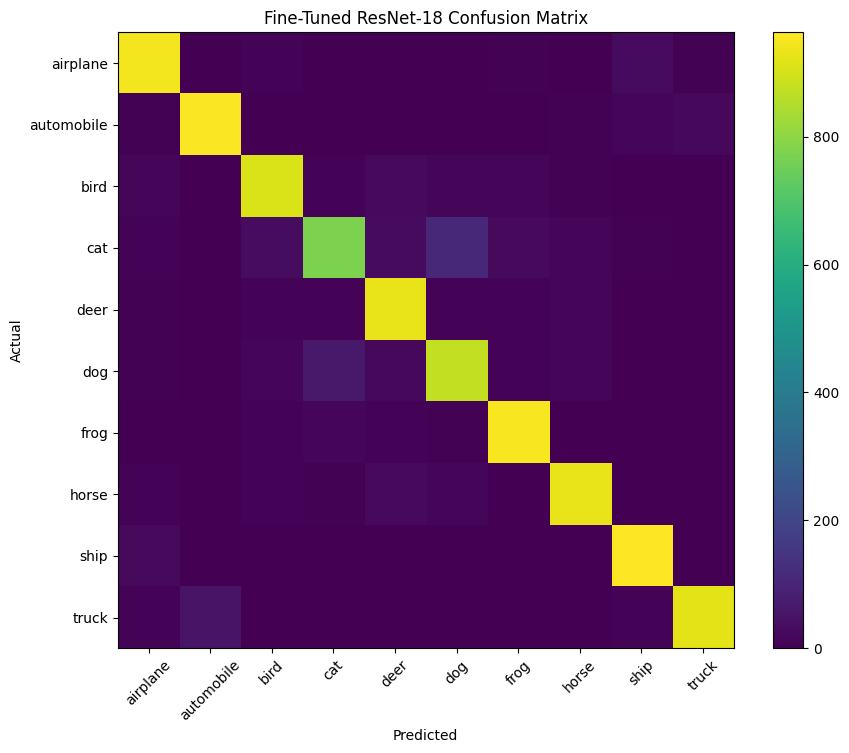

In [49]:
cm = confusion_matrix(
    all_labels_finetuned,
    all_predictions_finetuned
)

plt.figure(figsize=(10, 8))
plt.imshow(cm)
plt.xticks(range(10), classes, rotation=45)
plt.yticks(range(10), classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fine-Tuned ResNet-18 Confusion Matrix")
plt.colorbar()
plt.show()

In [50]:
from google.colab import files

uploaded = files.upload()

Saving tim-mossholder-WyDXNgmq8RE-unsplash.jpg to tim-mossholder-WyDXNgmq8RE-unsplash.jpg


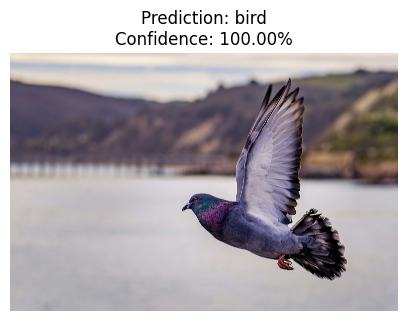

Predicted Class: bird
Confidence: 100.00%


In [51]:
from PIL import Image
import torch
import matplotlib.pyplot as plt

# Get uploaded file name
image_path = list(uploaded.keys())[0]

# Open image
image = Image.open(image_path).convert("RGB")

# Apply the same preprocessing used for ResNet
input_image = test_transform_resnet(image)

# Add batch dimension
input_image = input_image.unsqueeze(0).to(device)

# Prediction
resnet.eval()

with torch.no_grad():
    output = resnet(input_image)

    probabilities = torch.softmax(output, dim=1)
    confidence, predicted_class = torch.max(probabilities, 1)

predicted_label = classes[predicted_class.item()]
confidence_value = confidence.item() * 100

# Display image
plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(
    f"Prediction: {predicted_label}\n"
    f"Confidence: {confidence_value:.2f}%"
)
plt.axis("off")
plt.show()

print("Predicted Class:", predicted_label)
print(f"Confidence: {confidence_value:.2f}%")

In [52]:
print("========== MODEL COMPARISON ==========")

print(f"Basic CNN:              {accuracy:.2f}%")
print(f"ResNet-18:              {resnet_accuracy * 100:.2f}%")
print(f"Fine-Tuned ResNet-18:   {finetuned_accuracy * 100:.2f}%")

========== MODEL COMPARISON ==========
Basic CNN:              71.41%
ResNet-18:              80.78%
Fine-Tuned ResNet-18:   91.61%


In [53]:
improved_model = model

improved_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = improved_model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

improved_accuracy = 100 * correct / total

print(f"Improved CNN Accuracy: {improved_accuracy:.2f}%")

Improved CNN Accuracy: 72.33%


In [54]:
print("\n========== FINAL MODEL COMPARISON ==========")
print(f"Basic CNN:              {accuracy:.2f}%")
print(f"Improved CNN:           {improved_accuracy:.2f}%")
print(f"ResNet-18:              {resnet_accuracy * 100:.2f}%")
print(f"Fine-Tuned ResNet-18:   {finetuned_accuracy * 100:.2f}%")


========== FINAL MODEL COMPARISON ==========
Basic CNN:              71.41%
Improved CNN:           72.33%
ResNet-18:              80.78%
Fine-Tuned ResNet-18:   91.61%


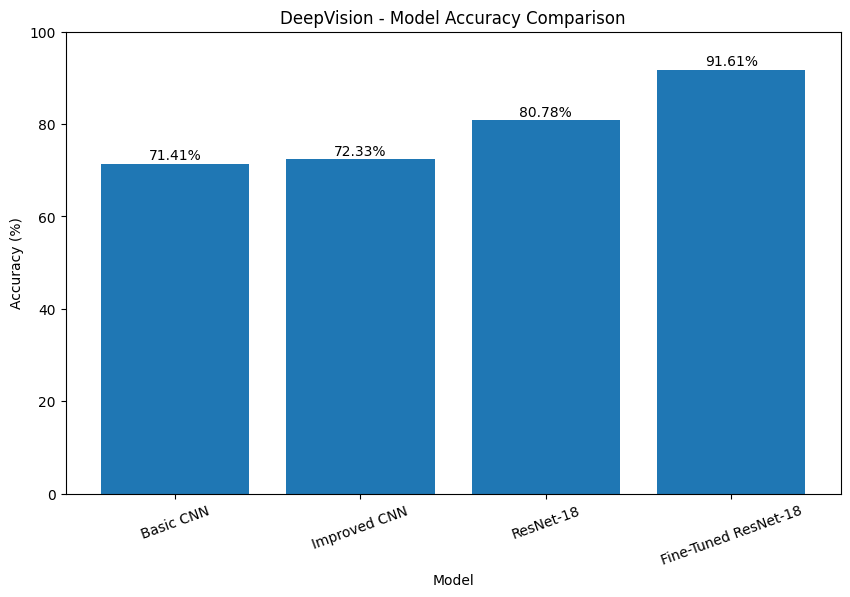

In [55]:
import matplotlib.pyplot as plt

models = [
    "Basic CNN",
    "Improved CNN",
    "ResNet-18",
    "Fine-Tuned ResNet-18"
]

accuracies = [
    accuracy,
    improved_accuracy,
    resnet_accuracy * 100,
    finetuned_accuracy * 100
]

plt.figure(figsize=(10, 6))
plt.bar(models, accuracies)

plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.title("DeepVision - Model Accuracy Comparison")
plt.ylim(0, 100)
plt.xticks(rotation=20)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()

In [56]:
torch.save(
    resnet.state_dict(),
    "deepvision_resnet18_cifar10.pth"
)

print("Model saved successfully!")

Model saved successfully!


In [57]:
import json

with open("classes.json", "w") as f:
    json.dump(classes, f)

print("Classes saved successfully!")

Classes saved successfully!


In [58]:
from google.colab import files

files.download("deepvision_resnet18_cifar10.pth")
files.download("classes.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [59]:
!pip install -q gradio

In [60]:
import gradio as gr
import torch
from PIL import Image

def predict_image(image):
    # Preprocess image
    input_image = test_transform_resnet(image)
    input_image = input_image.unsqueeze(0).to(device)

    # Prediction
    resnet.eval()

    with torch.no_grad():
        output = resnet(input_image)
        probabilities = torch.softmax(output, dim=1)

    # Return probabilities for all classes
    result = {
        classes[i]: float(probabilities[0][i])
        for i in range(len(classes))
    }

    return result


demo = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=3),
    title="DeepVision - CIFAR-10 Image Classifier",
    description="Upload an image and DeepVision will predict its class."
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://51cfd441fb74a3a44b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
